# Checkpoint 1 Alura — Café e qualidade do sono

Projeto para a Health&Life Analytics. Exploramos as relações entre consumo de café, estresse e sono em uma base sintética de 10.000 participantes. Em seguida, estimamos a qualidade do sono a partir de hábitos e características disponíveis antes da avaliação do sono.

## 1. Análise exploratória

In [1]:
from pathlib import Path
from urllib.request import urlretrieve

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
fonte = "https://cdn3.gnarususercontent.com.br/5209-projeto-cientista-dados-nivel-1/synthetic_coffee_health_10000%28in%29.csv"
arquivo = Path("data/coffee.csv")
if not arquivo.exists():
    arquivo.parent.mkdir(exist_ok=True)
    urlretrieve(fonte, arquivo)

# A categoria literal "None" significa ausência de problemas de saúde.
dados = pd.read_csv(arquivo, keep_default_na=False, na_values=[""])
display(pd.DataFrame({"tipo": dados.dtypes, "nulos": dados.isna().sum(),
                      "valores distintos": dados.nunique()}))
print(f"Dimensões: {dados.shape}; linhas duplicadas: {dados.duplicated().sum()}; "
      f"IDs repetidos: {dados.ID.duplicated().sum()}")
dados = dados.drop_duplicates()
numericas = ["Age", "Coffee_Intake", "Caffeine_mg", "Sleep_Hours", "BMI",
             "Heart_Rate", "Physical_Activity_Hours"]
categoricas = ["Gender", "Country", "Sleep_Quality", "Stress_Level",
               "Health_Issues", "Occupation", "Smoking", "Alcohol_Consumption"]
display(dados[numericas].describe().round(2))
display(dados[categoricas].astype("category").describe())

,tipo,nulos,valores distintos
ID,int64,0,10000
Age,int64,0,59
Gender,object,0,3
Country,object,0,20
Coffee_Intake,float64,0,78
Caffeine_mg,float64,0,4277
Sleep_Hours,float64,0,71
Sleep_Quality,object,0,4
BMI,float64,0,220
Heart_Rate,int64,0,58


Dimensões: (10000, 16); linhas duplicadas: 0; IDs repetidos: 0


,Age,Coffee_Intake,Caffeine_mg,Sleep_Hours,BMI,Heart_Rate,Physical_Activity_Hours
count,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00
mean,34.95,2.51,238.41,6.64,23.99,70.62,7.49
std,11.16,1.45,137.75,1.22,3.91,9.82,4.32
min,18.00,0.00,0.00,3.00,15.00,50.00,0.00
25%,26.00,1.50,138.75,5.80,21.30,64.00,3.70
50%,34.00,2.50,235.40,6.60,24.00,71.00,7.50
75%,43.00,3.50,332.02,7.50,26.60,77.00,11.20
max,80.00,8.20,780.30,10.00,38.20,109.00,15.00


,Gender,Country,Sleep_Quality,Stress_Level,Health_Issues,Occupation,Smoking,Alcohol_Consumption
count,10000,10000,10000,10000,10000,10000,10000,10000
unique,3,20,4,3,4,5,2,2
top,Female,Canada,Good,Low,None,Office,0,0
freq,5001,543,5637,6989,5941,2073,7996,6993


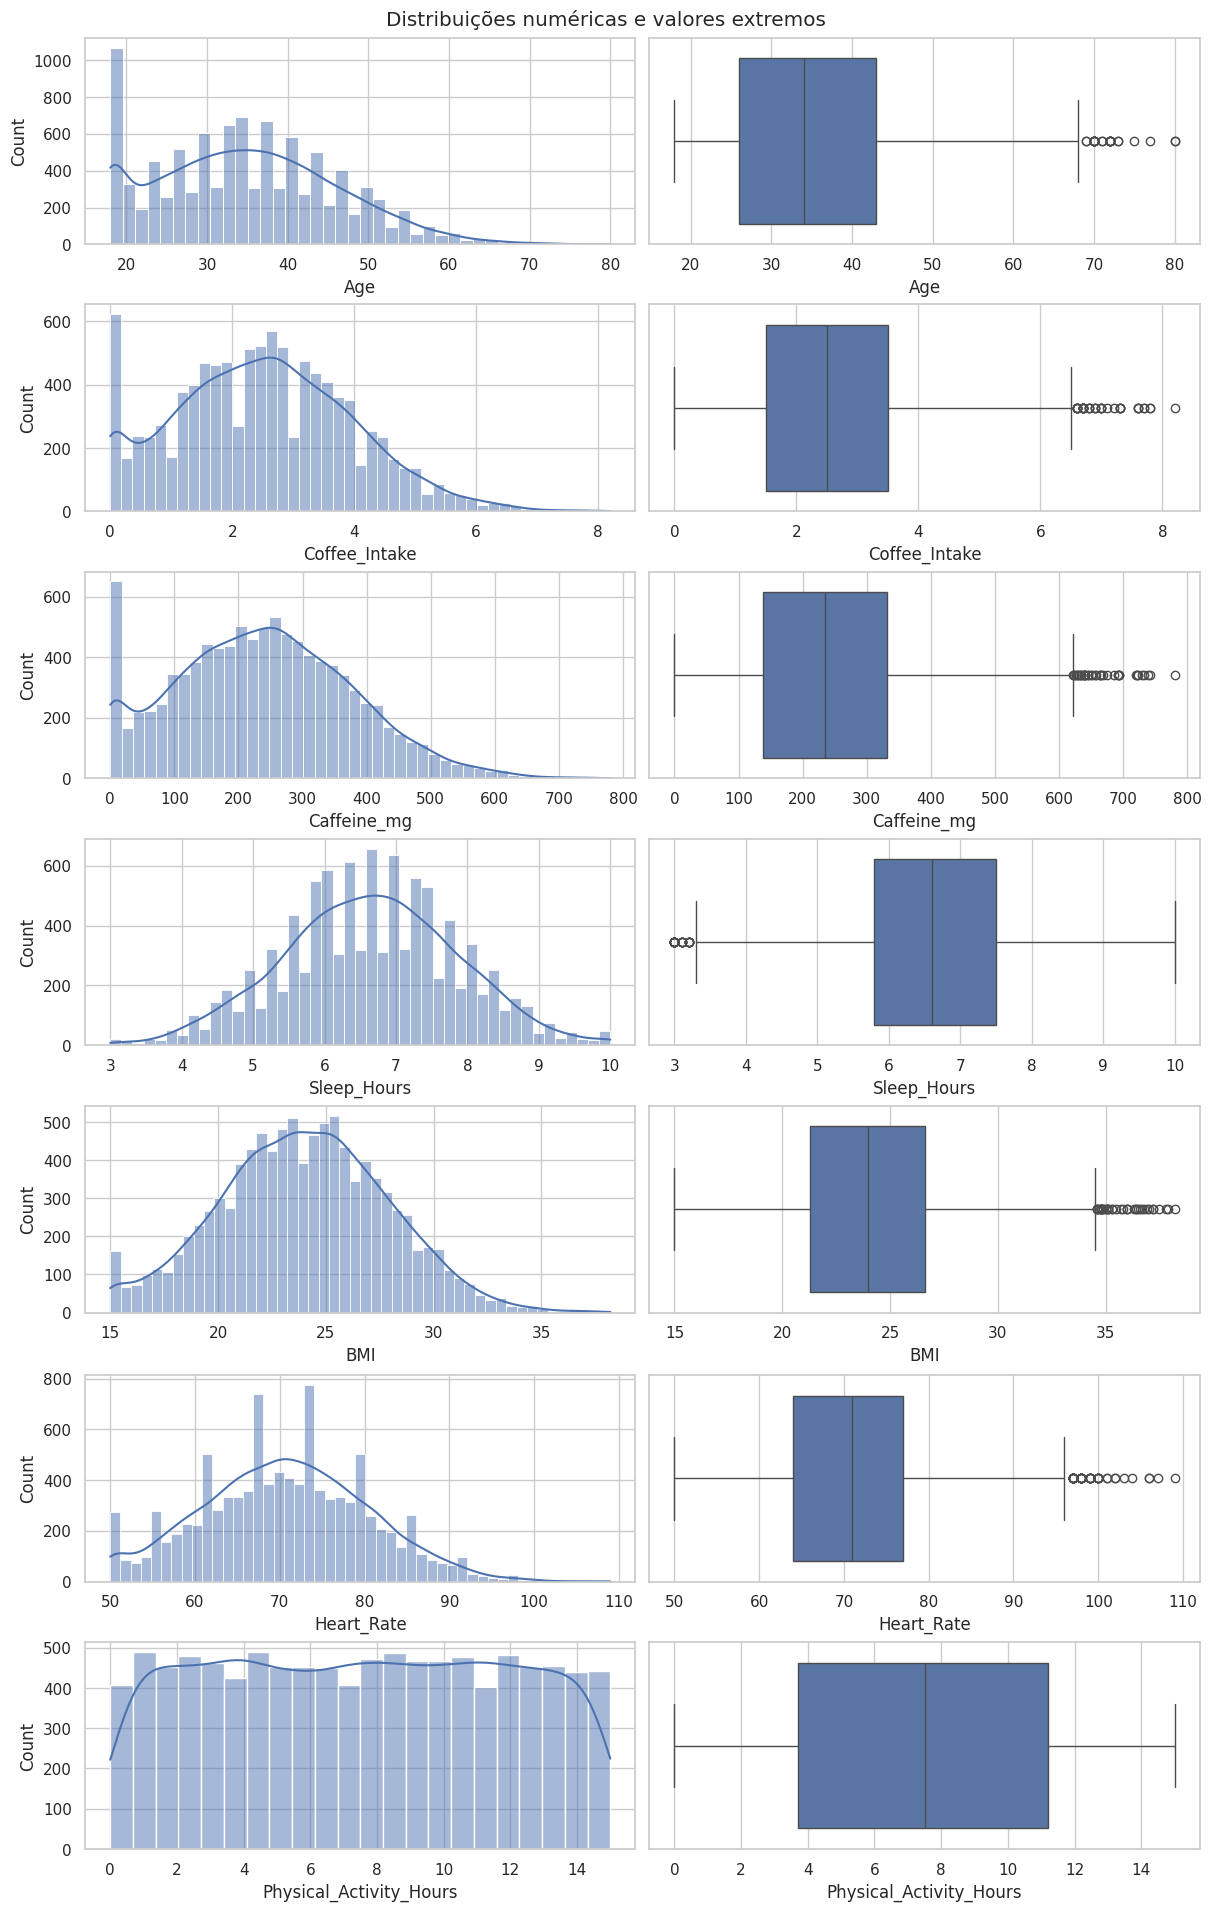

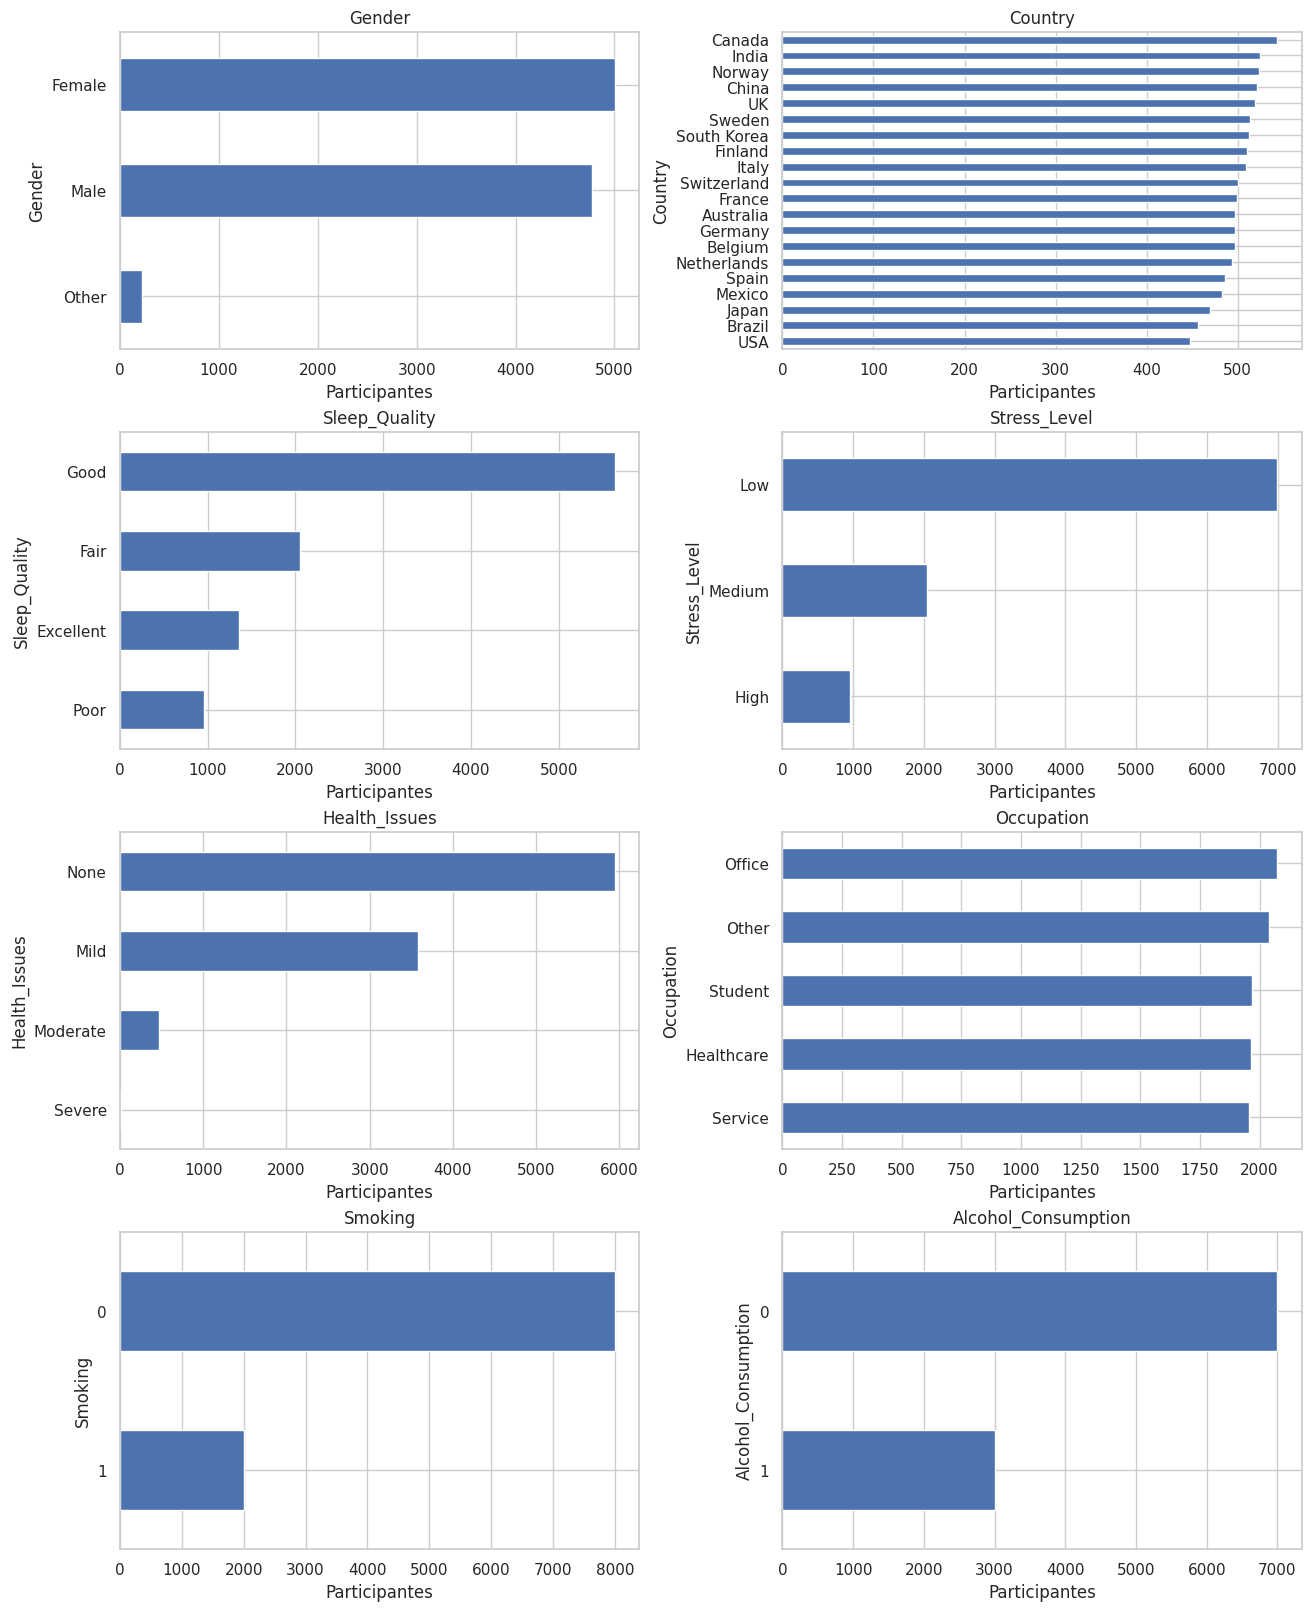

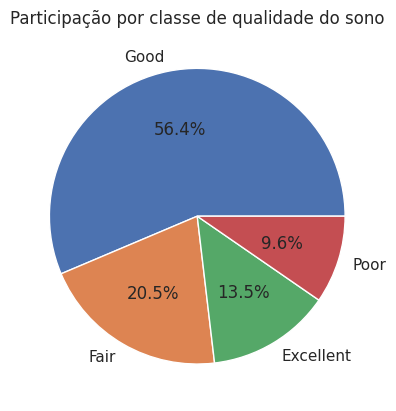

In [2]:
fig, eixos = plt.subplots(len(numericas), 2, figsize=(12, 19), layout="constrained")
for coluna, (hist, caixa) in zip(numericas, eixos):
    sns.histplot(data=dados, x=coluna, kde=True, ax=hist)
    sns.boxplot(data=dados, x=coluna, ax=caixa)
fig.suptitle("Distribuições numéricas e valores extremos")
plt.show()

fig, eixos = plt.subplots(4, 2, figsize=(13, 16), layout="constrained")
for coluna, ax in zip(categoricas, eixos.flat):
    dados[coluna].value_counts().sort_values().plot.barh(ax=ax)
    ax.set(title=coluna, xlabel="Participantes")
plt.show()

dados.Sleep_Quality.value_counts().plot.pie(autopct="%1.1f%%", ylabel="",
                                           title="Participação por classe de qualidade do sono")
plt.show()

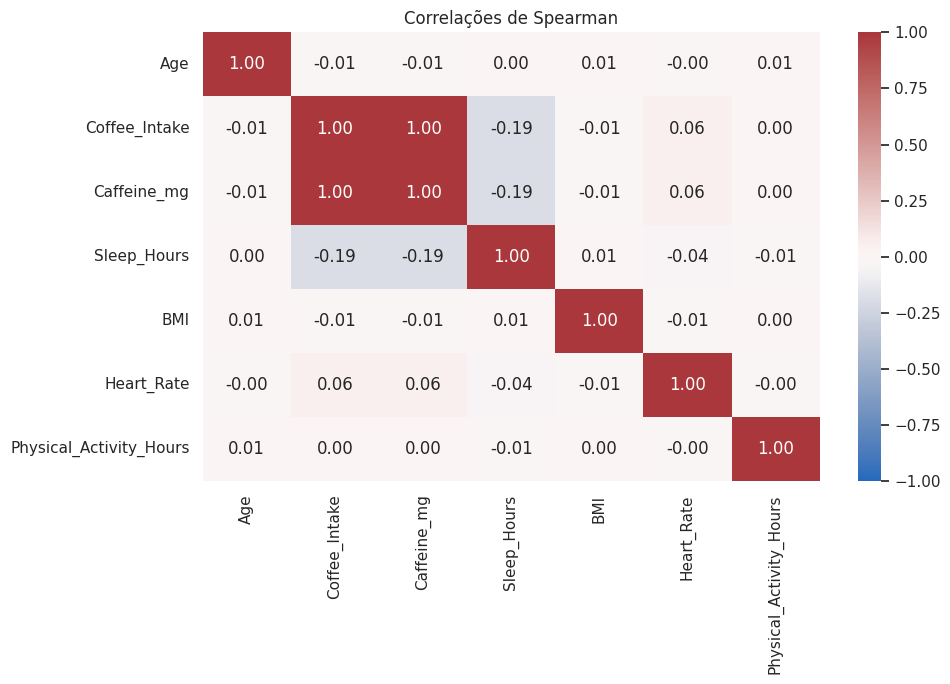

Sleep_Quality,Poor,Fair,Good,Excellent
Stress_Level,,,,
Low,0.0,0.0,80.7,19.3
Medium,0.0,100.0,0.0,0.0
High,100.0,0.0,0.0,0.0


In [3]:
ordem_sono = ["Poor", "Fair", "Good", "Excellent"]
ordem_estresse = ["Low", "Medium", "High"]
correlacao = dados[numericas].corr(method="spearman")
plt.figure(figsize=(10, 7))
sns.heatmap(correlacao, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1)
plt.title("Correlações de Spearman")
plt.tight_layout()
plt.show()

estresse_sono = pd.crosstab(dados.Stress_Level, dados.Sleep_Quality, normalize="index")
estresse_sono = estresse_sono.reindex(index=ordem_estresse, columns=ordem_sono) * 100
display(estresse_sono.round(1))

A base tem 10.000 registros e 16 colunas, sem campos vazios, linhas duplicadas ou IDs repetidos. A classe `Good` representa 56,4% da amostra e a classe `Poor`, 9,6%. Esse desequilíbrio motiva o uso de F1 macro na avaliação. O consumo em xícaras e a estimativa em mg têm correlação de Spearman de 0,9998, o que indica forte redundância entre as duas medidas.

## 2. Visualização e insights

As faixas de idade são 18–29, 30–44, 45–59 e 60+. Os grupos de cafeína usam o primeiro e o terceiro quartis observados na base. Esses limites servem à comparação descritiva.

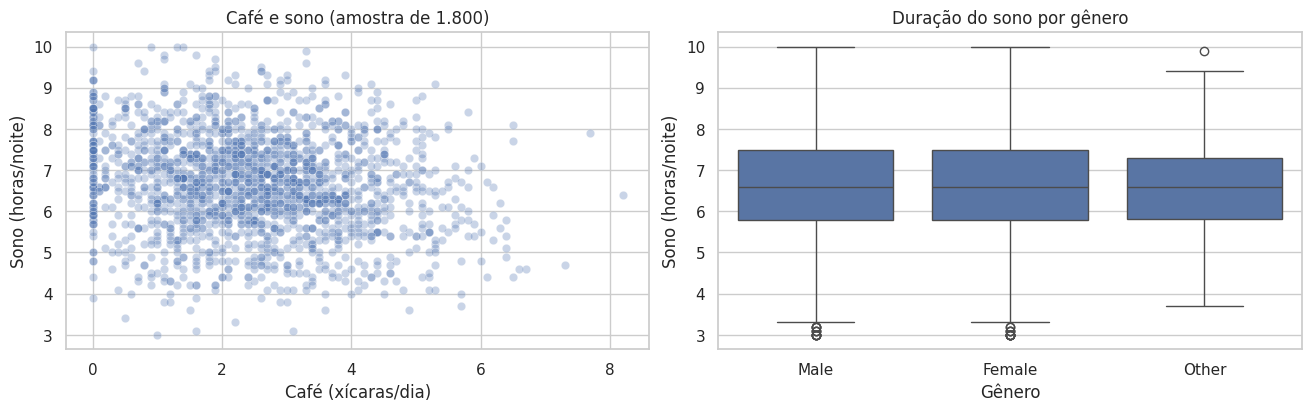

,size,mean,median
Gender,,,
Female,5001,6.64,6.6
Male,4773,6.64,6.6
Other,226,6.59,6.6


participantes  cafe_medio  sono_medio
Faixa_Idade Stress_Level                                       
18–29       High                    320        3.05        4.44
            Low                    2361        2.40        7.24
            Medium                  707        2.78        5.58
30–44       High                    442        2.91        4.44
            Low                    3206        2.36        7.27
            Medium                  950        2.77        5.58
45–59       High                    181        3.04        4.50
            Low                    1294        2.33        7.21
            Medium                  354        2.74        5.58
60+         High                     18        2.94        4.49
            Low                     128        2.30        7.25
            Medium                   39        2.55        5.54

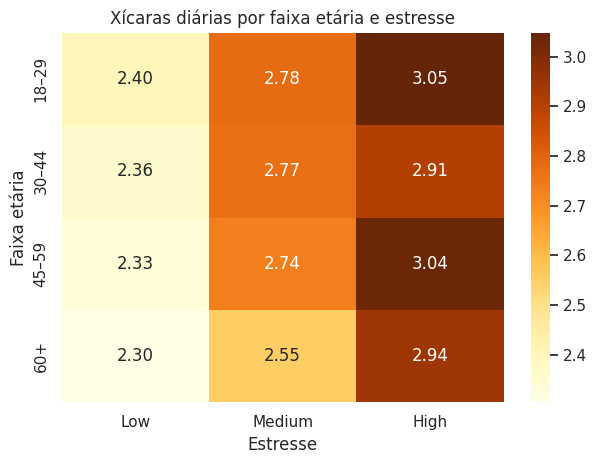

In [4]:
q1, q3 = dados.Caffeine_mg.quantile([.25, .75])
grupos = ["Baixa", "Intermediária", "Alta"]
dados = dados.assign(
    Faixa_Idade=pd.cut(dados.Age, [18, 30, 45, 60, np.inf], right=False,
                       labels=["18–29", "30–44", "45–59", "60+"]),
    Faixa_Cafeina=pd.cut(dados.Caffeine_mg, [-np.inf, q1, q3, np.inf], labels=grupos),
)
fig, eixos = plt.subplots(1, 2, figsize=(13, 4), layout="constrained")
sns.scatterplot(data=dados.sample(1800, random_state=42), x="Coffee_Intake",
                y="Sleep_Hours", alpha=.3, ax=eixos[0])
eixos[0].set(title="Café e sono (amostra de 1.800)", xlabel="Café (xícaras/dia)",
             ylabel="Sono (horas/noite)")
sns.boxplot(data=dados, x="Gender", y="Sleep_Hours", ax=eixos[1])
eixos[1].set(title="Duração do sono por gênero", xlabel="Gênero", ylabel="Sono (horas/noite)")
plt.show()
display(dados.groupby("Gender").Sleep_Hours.agg(["size", "mean", "median"]).round(2))

segmentos = dados.groupby(["Faixa_Idade", "Stress_Level"], observed=True).agg(
    participantes=("ID", "size"), cafe_medio=("Coffee_Intake", "mean"),
    sono_medio=("Sleep_Hours", "mean"))
display(segmentos.round(2))
cafe_por_grupo = segmentos.cafe_medio.unstack().reindex(columns=ordem_estresse)
sns.heatmap(cafe_por_grupo, annot=True, fmt=".2f", cmap="YlOrBr")
plt.title("Xícaras diárias por faixa etária e estresse")
plt.xlabel("Estresse")
plt.ylabel("Faixa etária")
plt.tight_layout()
plt.show()

### Principais Descobertas

,size,mean
Faixa_Cafeina,,
Baixa,2500,6.93
Intermediária,5000,6.64
Alta,2500,6.33


- As médias de sono nos grupos de cafeína alta (> 332.0 mg/dia) e baixa (≤ 138.8 mg/dia) foram **6.33 h** e **6.93 h**, respectivamente. A diferença alta − baixa foi de **-0.59 h/noite**. A correlação de Spearman entre xícaras e horas de sono foi **-0.19**.
- A proporção de sono classificado como Poor foi **100.0%** com estresse alto e **0.0%** com estresse baixo.
- A amplitude entre as médias de duração do sono por gênero foi de **0.04 h**.
- As comparações são descritivas e refletem uma base sintética.

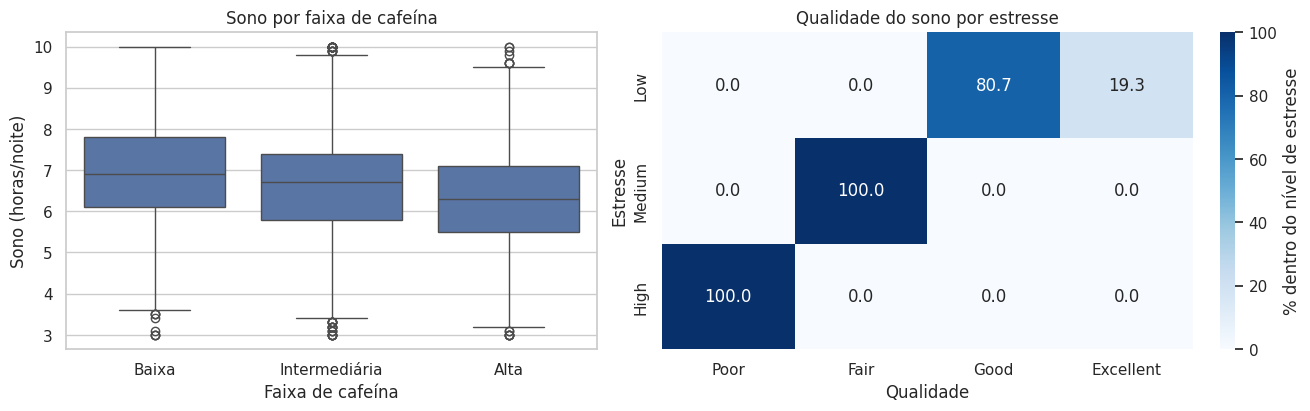

In [5]:
from IPython.display import Markdown, display

resumo = dados.groupby("Faixa_Cafeina", observed=True).Sleep_Hours.agg(["size", "mean"])
display(resumo.round(2))
delta = resumo.loc["Alta", "mean"] - resumo.loc["Baixa", "mean"]
genero = dados.groupby("Gender").Sleep_Hours.mean()
pior_sono = estresse_sono.Poor
display(Markdown(
    f"- As médias de sono nos grupos de cafeína alta (> {q3:.1f} mg/dia) e baixa "
    f"(≤ {q1:.1f} mg/dia) foram **{resumo.loc['Alta', 'mean']:.2f} h** e "
    f"**{resumo.loc['Baixa', 'mean']:.2f} h**, respectivamente. A diferença alta − baixa "
    f"foi de **{delta:+.2f} h/noite**. A correlação de Spearman entre xícaras e horas "
    f"de sono foi **{correlacao.loc['Coffee_Intake', 'Sleep_Hours']:.2f}**.\n"
    f"- A proporção de sono classificado como Poor foi **{pior_sono.High:.1f}%** "
    f"com estresse alto e **{pior_sono.Low:.1f}%** com estresse baixo.\n"
    f"- A amplitude entre as médias de duração do sono por gênero foi de "
    f"**{genero.max() - genero.min():.2f} h**.\n"
    "- As comparações são descritivas e refletem uma base sintética."
))
fig, eixos = plt.subplots(1, 2, figsize=(13, 4), layout="constrained")
sns.boxplot(data=dados, x="Faixa_Cafeina", y="Sleep_Hours", ax=eixos[0])
eixos[0].set(title="Sono por faixa de cafeína", xlabel="Faixa de cafeína",
             ylabel="Sono (horas/noite)")
sns.heatmap(estresse_sono, annot=True, fmt=".1f", cmap="Blues", ax=eixos[1],
            cbar_kws={"label": "% dentro do nível de estresse"})
eixos[1].set(title="Qualidade do sono por estresse", xlabel="Qualidade", ylabel="Estresse")
plt.show()

## 3. Modelo preditivo

Usamos cafeína em mg e descartamos xícaras como preditor redundante. Excluímos ID e horas de sono. Horas de sono podem ter sido usadas para gerar o alvo sintético. Estresse também pode refletir regras da geração sintética, então a avaliação principal o exclui. A variável derivada `Atividade_Diaria_Horas` converte a atividade semanal em uma média diária e `Cafeina_por_IMC` combina a ingestão de cafeína com o IMC. O pré-processamento aprende imputações, escala e categorias dentro de cada partição de treino.

A seleção usa F1 macro médio em cinco dobras estratificadas no treino para dar peso igual às classes. Reservamos 20% dos registros para teste. A classe mais frequente serve de referência.

,F1 treino CV,F1 validação CV,Desvio F1 validação,Acurácia teste,F1 macro teste
Modelo,,,,,
Floresta aleatória,0.634,0.499,0.007,0.600,0.504
Regressão logística,0.492,0.457,0.012,0.508,0.464
Referência (classe majoritária),0.180,0.180,0.000,0.564,0.180


Regressão logística
              precision    recall  f1-score   support

        Poor       0.28      0.51      0.36       192
        Fair       0.60      0.50      0.55       410
        Good       0.83      0.51      0.63      1128
   Excellent       0.23      0.52      0.32       270

    accuracy                           0.51      2000
   macro avg       0.49      0.51      0.46      2000
weighted avg       0.65      0.51      0.54      2000

Floresta aleatória
              precision    recall  f1-score   support

        Poor       0.30      0.34      0.32       192
        Fair       0.63      0.64      0.64       410
        Good       0.84      0.67      0.75      1128
   Excellent       0.25      0.43      0.31       270

    accuracy                           0.60      2000
   macro avg       0.50      0.52      0.50      2000
weighted avg       0.67      0.60      0.62      2000



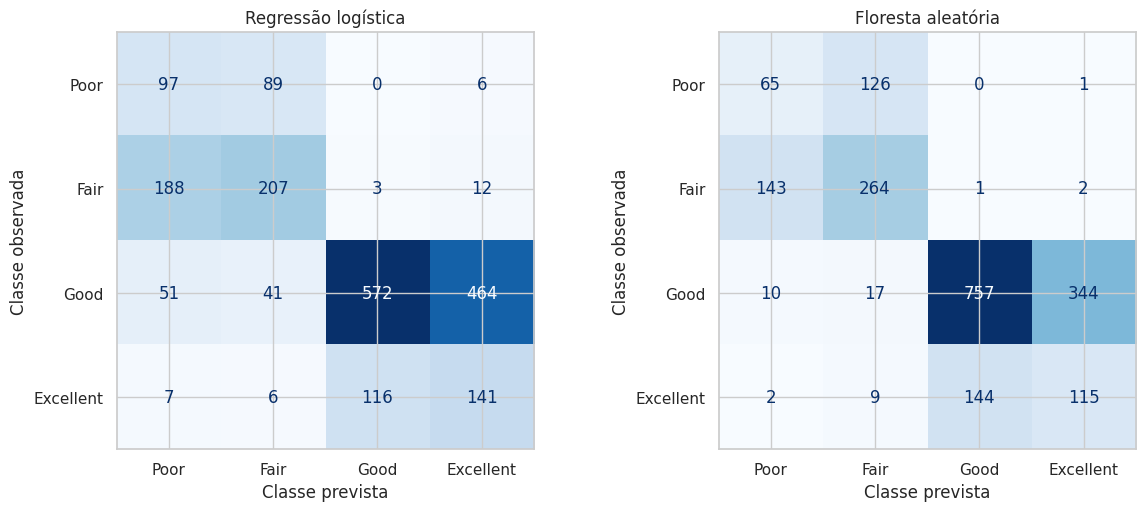

**Floresta aleatória** teve o maior F1 macro na validação entre os dois classificadores, com **0.499**. No teste, obteve **60.1%** de acurácia e **0.504** de F1 macro, frente a **0.180** da referência. A lacuna de F1 entre treino e validação foi de **0.135**. A lacuna sugere sobreajuste. O desempenho fora do treino indica capacidade limitada de distinguir as quatro classes. Isso pode refletir sinal limitado nas variáveis disponíveis ou subajuste.

In [6]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report,
                             f1_score)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

# Função definida em módulo importável para que o pipeline salvo possa ser recarregado.
from features import derivar_features

colunas_num = ["Age", "Caffeine_mg", "BMI", "Heart_Rate", "Atividade_Diaria_Horas",
               "Cafeina_por_IMC"]
colunas_cat = ["Gender", "Country", "Health_Issues", "Occupation",
               "Smoking", "Alcohol_Consumption"]
X = dados[colunas_num[:4] + ["Physical_Activity_Hours"] + colunas_cat]
y = dados.Sleep_Quality
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=.2, stratify=y, random_state=42,
)

preparo = ColumnTransformer([
    ("num", Pipeline([("imputar", SimpleImputer(strategy="median")),
                      ("escalar", StandardScaler())]), colunas_num),
    ("cat", Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                      ("codificar", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]),
     colunas_cat),
])
modelos = {
    "Referência (classe majoritária)": DummyClassifier(strategy="most_frequent"),
    "Regressão logística": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Floresta aleatória": RandomForestClassifier(n_estimators=120, max_depth=8,
                                               min_samples_leaf=12, class_weight="balanced",
                                               random_state=42, n_jobs=2),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
resultados, ajustados = [], {}
for nome, estimador in modelos.items():
    pipeline = Pipeline([("derivar", FunctionTransformer(derivar_features)),
                         ("preparar", clone(preparo)), ("classificar", estimador)])
    notas = cross_validate(pipeline, X_treino, y_treino, cv=cv, scoring="f1_macro",
                           return_train_score=True)
    ajustados[nome] = pipeline.fit(X_treino, y_treino)
    resultados.append({"Modelo": nome, "F1 treino CV": notas["train_score"].mean(),
                       "F1 validação CV": notas["test_score"].mean(),
                       "Desvio F1 validação": notas["test_score"].std()})

metricas = pd.DataFrame(resultados).set_index("Modelo").sort_values(
    "F1 validação CV", ascending=False)
vencedor = metricas.drop(index="Referência (classe majoritária)").index[0]
for nome, pipeline in ajustados.items():
    previsoes = pipeline.predict(X_teste)
    metricas.loc[nome, "Acurácia teste"] = accuracy_score(y_teste, previsoes)
    metricas.loc[nome, "F1 macro teste"] = f1_score(y_teste, previsoes, average="macro")
display(metricas.round(3))

melhor = ajustados[vencedor]
fig, eixos = plt.subplots(1, 2, figsize=(12, 5), layout="constrained")
for (nome, pipeline), ax in zip(list(ajustados.items())[1:], eixos):
    previsoes = pipeline.predict(X_teste)
    print(nome)
    print(classification_report(y_teste, previsoes, labels=ordem_sono, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(y_teste, previsoes, labels=ordem_sono,
                                           cmap="Blues", colorbar=False, ax=ax)
    ax.set(title=nome, xlabel="Classe prevista", ylabel="Classe observada")
plt.show()

linha = metricas.loc[vencedor]
lacuna = linha["F1 treino CV"] - linha["F1 validação CV"]
f1_referencia = metricas.loc["Referência (classe majoritária)", "F1 macro teste"]
display(Markdown(
    f"**{vencedor}** teve o maior F1 macro na validação entre os dois classificadores, "
    f"com **{linha['F1 validação CV']:.3f}**. No teste, obteve "
    f"**{linha['Acurácia teste']:.1%}** de acurácia e **{linha['F1 macro teste']:.3f}** "
    f"de F1 macro, frente a **{f1_referencia:.3f}** da referência. "
    f"A lacuna de F1 entre treino e validação foi de **{lacuna:.3f}**. "
    + ("A lacuna sugere sobreajuste. "
       if lacuna > .08 else "A lacuna oferece pouca evidência de sobreajuste. ")
    + ("O desempenho fora do treino indica capacidade limitada de distinguir as quatro classes. "
       "Isso pode refletir sinal limitado nas variáveis disponíveis ou subajuste."
       if linha["F1 validação CV"] < .5 else
       "O relatório por classe mostra onde ainda há perdas de desempenho.")
))

In [7]:
pasta_modelo = Path("models")
pasta_modelo.mkdir(exist_ok=True)
joblib.dump(melhor, pasta_modelo / "sleep_quality.joblib", compress=3)

# Exporta as features efetivamente usadas pelo modelo e identifica cada partição.
transformado = melhor[:-1].transform(X)
processado = pd.DataFrame(transformado, index=X.index,
                         columns=melhor.named_steps["preparar"].get_feature_names_out())
processado["Sleep_Quality"] = y
processado["Particao"] = np.where(processado.index.isin(X_treino.index), "treino", "teste")
processado.to_csv("data/coffee_processed.csv", index=False, float_format="%.8g")

recarregado = joblib.load(pasta_modelo / "sleep_quality.joblib")
np.testing.assert_array_equal(recarregado.predict(X_teste), melhor.predict(X_teste))
assert len(pd.read_csv("data/coffee_processed.csv")) == len(X)

### Recomendações para o Negócio

- Use as diferenças de duração do sono por faixa de cafeína para formular hipóteses de acompanhamento. Registre quantidade, horário de ingestão e horas de sono em um diário voluntário. Compare as mudanças ao longo do tempo dentro do mesmo participante.
- Considere o estresse ao interpretar os relatos de sono. A tabela de proporções ajuda a definir hipóteses para investigar com dados reais, como a concentração de relatos de sono ruim entre participantes com estresse alto.
- Use o modelo como protótipo de análise. Antes de orientar clientes individualmente, valide o desempenho em dados reais e revise o desempenho e os erros por classe e por grupo.